<div style="border-left:4px solid #3D6FB0;padding:6px 0 8px 16px;"><div style="opacity:.72;font-size:12px;letter-spacing:1.4px;">DATOS MASIVOS II · PRÁCTICA</div><div style="color:#3D6FB0;font-size:27px;font-weight:700;margin-top:4px;">Reglas de asociación y patrones secuenciales</div><div style="opacity:.72;font-size:14px;margin-top:6px;">Itemsets frecuentes con A-Priori, PCY, Multistage, Multihash, SON, Toivonen y FP-Growth sobre las películas que le gustaron a cada usuario; reglas "a quienes les gustó X también les gustó Y"; PrefixSpan sobre las secuencias por fecha y recomendación de la siguiente película.</div><div style="opacity:.72;font-size:14px;margin-top:6px;margin-bottom:10px;">Equipo Tres: Castrillo Cruz Karen Arlet, Ramos González Nadia, Zamora Antiga Ángel Javier.</div><img src="https://mmss.iimas.unam.mx/dmmss/wp-content/uploads/2026/02/cropped-LogoUNAM_IIMAS_Negro50-scaled-2.png" width="200"/></div>

### Objetivo

Tratar a cada usuario como una **canasta**: el conjunto de películas que calificó con 4 o 5. Sobre las canastas buscamos
**itemsets frecuentes** y **reglas de asociación** (Leskovec *et al.*, *Mining of Massive Datasets*, cap. 6). Comparamos
en tiempo y memoria los algoritmos del curso: A-Priori, PCY, Multistage, Multihash, SON y Toivonen, todos implementados
por nosotros, y FP-Growth de `mlxtend` como referencia. Después ordenamos las canastas por fecha para buscar
**patrones secuenciales** con PrefixSpan y recomendar la siguiente película. Las reglas y los patrones se evalúan como
recomendadores top-N con el protocolo de los notebooks 2 y 3.

### Los datos

La submuestra S (`S_R_train.npz`, `S_dias.npy`) y el catálogo `peliculas.parquet`. **Submuestra de este notebook:**
**20,000 usuarios** de S elegidos al azar (semilla 42) entre los que tienen al menos un rating ≥ 4. Las 352 millones de
ocurrencias de pares de sus canastas ya bastan para que PCY y sus variantes muestren su comportamiento. Para PrefixSpan
usamos 10,000 de ellos y las 500 películas con más \"me gusta\" (sección 7).

### Contenido

1. **Canastas.**
2. **A-Priori.**
3. **PCY, Multistage y Multihash.**
4. **SON y Toivonen.**
5. **FP-Growth y comparación de los algoritmos.**
6. **Reglas de asociación** y recomendador top-N basado en reglas.
7. **PrefixSpan:** patrones secuenciales y recomendación de la siguiente película.
8. **Resumen.**

In [1]:
# Librerías, rutas, paleta y funciones auxiliares
import gc
import json
import math
import time
import tracemalloc
from itertools import combinations
from pathlib import Path

import numpy as np
import pandas as pd
import scipy.sparse as sp
import psutil
import matplotlib.pyplot as plt
from numba import njit
from mlxtend.frequent_patterns import fpgrowth
from IPython.display import display

%matplotlib inline
pd.set_option("display.max_columns", None)
pd.set_option("display.max_colwidth", 70)
pd.set_option("display.width", 220)

RUTA_PROCESADOS = Path("..") / "data" / "processed"
RUTA_RESULTADOS = RUTA_PROCESADOS / "resultados"
SEMILLA = 42

# Paleta única del notebook: azul principal, rojo de acento y grises neutros
AZUL, ROJO = "#3D6FB0", "#B03D3D"
GRIS, GRIS_CLARO, TINTA = "#8C8C8C", "#EEF1F6", "#333333"

plt.rcParams.update({
    "figure.dpi": 100, "font.size": 10, "axes.titlesize": 12, "axes.titleweight": "bold",
    "axes.titlelocation": "left", "axes.edgecolor": "#999999", "axes.labelcolor": TINTA,
    "xtick.color": TINTA, "ytick.color": TINTA, "legend.frameon": False,
})


def estilo_ejes(ax, titulo=None, xlabel=None, ylabel=None, rejilla="y"):
    # Estilo común de los ejes: título, etiquetas, sin bordes superior y derecho, rejilla tenue
    if titulo:
        ax.set_title(titulo)
    if xlabel:
        ax.set_xlabel(xlabel)
    if ylabel:
        ax.set_ylabel(ylabel)
    ax.spines[["top", "right"]].set_visible(False)
    if rejilla:
        ax.grid(axis=rejilla, color="#DDDDDD", linewidth=0.6)
        ax.set_axisbelow(True)


def pct(x, dec=2):
    return f"{100 * x:,.{dec}f} %"


def tamano(nbytes):
    if nbytes < 1e6:
        return f"{nbytes / 1e3:,.1f} KB"
    return f"{nbytes / 1e9:,.2f} GB" if nbytes >= 1e9 else f"{nbytes / 1e6:,.1f} MB"


registro_ram = []


def ram(paso):
    rss, libre = psutil.Process().memory_info().rss, psutil.virtual_memory().available
    registro_ram.append({"paso": paso, "RAM del proceso": tamano(rss), "RAM libre del sistema": tamano(libre)})
    print(f"[RAM] {paso}: proceso {tamano(rss)} | libre en el sistema {tamano(libre)}")


def guardar_resultado(modelo, **metricas):
    with open(RUTA_RESULTADOS / f"{modelo}.json", "w", encoding="utf-8") as f:
        json.dump({"modelo": modelo, **metricas}, f, ensure_ascii=False, indent=1)


ram("inicio")

[RAM] inicio: proceso 176.4 MB | libre en el sistema 7.23 GB


<div style="border-left:4px solid #3D6FB0;padding:4px 0 6px 14px;margin:16px 0 6px 0;"><span style="background:#3D6FB0;color:#FFFFFF;border-radius:3px;padding:2px 9px;font-size:11px;letter-spacing:.6px;">REGLAS · DATOS</span><br/><span style="color:#3D6FB0;font-size:21px;font-weight:700;">1. Canastas</span></div>



Una canasta es el conjunto de películas de S que un usuario calificó con **4 o 5** en el entrenamiento. Las guardamos
en formato CSR (`indptr`, `items`): la canasta $t$ son los ítems `items[indptr[t]:indptr[t+1]]`, ordenados. El
**soporte** de un itemset $I$ es el número de canastas que lo contienen, y es frecuente si su soporte es al menos $s$.

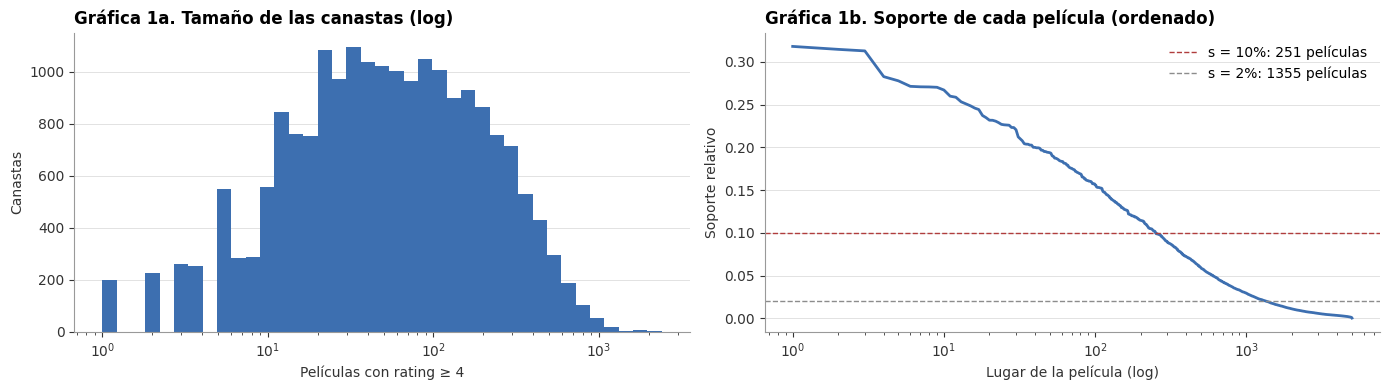

Canastas: 20,000 | tamaño medio 111.3, mediana 53, máximo 2,397 | ocurrencias de pares: 351,346,717 | películas con soporte > 0: 5,000


,película,soporte
1,The Green Mile (1999),31.8 %
2,Forrest Gump (1994),31.5 %
3,Pirates of the Caribbean: The Curse of the Black Pearl (2003),31.3 %
4,Independence Day (1996),28.3 %
5,Lord of the Rings: The Two Towers (2002),27.8 %
6,The Patriot (2000),27.1 %
7,Pretty Woman (1990),27.1 %
8,The Sixth Sense (1999),27.1 %


[RAM] 1. canastas: proceso 532.9 MB | libre en el sistema 6.88 GB


In [2]:
# Canastas de 20,000 usuarios de S: películas calificadas con 4 o 5
S_R = sp.load_npz(RUTA_PROCESADOS / "S_R_train.npz")
S_dias = np.load(RUTA_PROCESADOS / "S_dias.npy")
S_peliculas = np.load(RUTA_PROCESADOS / "S_peliculas.npy")
peliculas = pd.read_parquet(RUTA_PROCESADOS / "peliculas.parquet")
n_S_usr, N_ITEMS = S_R.shape
titulo = lambda i: f"{peliculas.loc[S_peliculas[i], 'title']} ({peliculas.loc[S_peliculas[i], 'year']})"

GUSTA = sp.csr_matrix(((S_R.data >= 4).astype(np.int8), S_R.indices.copy(), S_R.indptr.copy()), shape=S_R.shape)
GUSTA.eliminate_zeros()  # con copias: eliminate_zeros modifica los arreglos en su lugar
con_gustos = np.flatnonzero(np.diff(GUSTA.indptr) > 0)
USUARIOS_T = np.sort(np.random.default_rng(SEMILLA).choice(con_gustos, 20_000, replace=False))
T = GUSTA[USUARIOS_T]
T.sort_indices()
indptr, items = T.indptr.astype(np.int64), T.indices.astype(np.int64)
N_T = len(USUARIOS_T)
tam = np.diff(indptr)
soporte_item = np.bincount(items, minlength=N_ITEMS)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 4))
ax1.hist(tam, bins=np.logspace(0, np.log10(tam.max()), 40), color=AZUL)
ax1.set_xscale("log")
estilo_ejes(ax1, "Gráfica 1a. Tamaño de las canastas (log)", "Películas con rating ≥ 4", "Canastas")
orden_sop = np.sort(soporte_item)[::-1] / N_T
ax2.plot(np.arange(1, N_ITEMS + 1), orden_sop, color=AZUL, linewidth=2)
for s, c in [(0.10, ROJO), (0.02, GRIS)]:
    ax2.axhline(s, color=c, linestyle="--", linewidth=1, label=f"s = {s:.0%}: {(orden_sop >= s).sum()} películas")
ax2.set_xscale("log")
ax2.legend()
estilo_ejes(ax2, "Gráfica 1b. Soporte de cada película (ordenado)", "Lugar de la película (log)", "Soporte relativo")
plt.tight_layout()
plt.show()
print(f"Canastas: {N_T:,} | tamaño medio {tam.mean():.1f}, mediana {np.median(tam):.0f}, máximo {tam.max():,} | "
      f"ocurrencias de pares: {(tam.astype(np.int64) * (tam - 1) // 2).sum():,} | películas con soporte > 0: "
      f"{(soporte_item > 0).sum():,}")
display(pd.DataFrame({"película": [titulo(i) for i in np.argsort(-soporte_item)[:8]],
                      "soporte": [pct(soporte_item[i] / N_T, 1) for i in np.argsort(-soporte_item)[:8]]}, index=range(1, 9)))
ram("1. canastas")

**Observaciones: canastas**

- **Tamaño.** Las 20,000 canastas tienen en promedio **111** películas con rating ≥ 4 (mediana 53, máximo 2,397) y
  suman **351 millones** de ocurrencias de pares. Son canastas mucho más grandes que las de un supermercado, y eso
  pesa en PCY (sección 3), que hace *hash* de todos los pares en su primera pasada.
- **Soporte (Gráfica 1b).** La película con más "me gusta", *The Green Mile*, está en el **31.8 %** de las canastas.
  Con $s = 10\,\%$ son frecuentes **251** películas y con $s = 2\,\%$, **1,355**. Por la cola larga, cualquier
  umbral razonable deja fuera a la mayoría del catálogo: las reglas hablan de películas populares.

<div style="border-left:4px solid #3D6FB0;padding:4px 0 6px 14px;margin:16px 0 6px 0;"><span style="background:#3D6FB0;color:#FFFFFF;border-radius:3px;padding:2px 9px;font-size:11px;letter-spacing:.6px;">REGLAS · A-PRIORI</span><br/><span style="color:#3D6FB0;font-size:21px;font-weight:700;">2. A-Priori</span></div>



**Monotonía.** Si un itemset es frecuente, todos sus subconjuntos lo son. A-Priori hace una pasada por tamaño $k$ y
solo cuenta los **candidatos** $C_k$ cuyos subconjuntos de tamaño $k-1$ son todos frecuentes (MMDS, sección 6.2):

- **pasada 1:** cuenta cada película y se queda con las frecuentes $L_1$;
- **pasada 2:** cuenta los pares de películas de $L_1$ en un **arreglo triangular** de $\binom{|L_1|}{2}$ enteros, la
  estructura más compacta cuando casi todos los pares aparecen;
- **pasadas $k \ge 3$:** genera $C_k$ uniendo los itemsets de $L_{k-1}$ que comparten sus $k-2$ primeros ítems y poda los
  que tienen un subconjunto no frecuente. Los cuenta recorriendo las canastas, con los candidatos agrupados por su
  primer ítem.

Los conteos están compilados con `numba`. Usamos **$s = 10\,\%$** de las canastas (2,000 usuarios): es lo bastante bajo
para obtener itemsets de varios tamaños y lo bastante alto para que las reglas tengan respaldo.

In [3]:
@njit
def contar_pares_triangular(indptr, items, rango, F):
    # Pasada 2 de A-Priori: pares de ítems frecuentes en un arreglo triangular
    tri = np.zeros(F * (F - 1) // 2, np.int32)
    buf = np.empty(5000, np.int64)
    for t in range(len(indptr) - 1):
        m = 0
        for p in range(indptr[t], indptr[t + 1]):
            r = rango[items[p]]
            if r >= 0:
                buf[m] = r
                m += 1
        orden = np.sort(buf[:m])
        for a in range(m):
            i = orden[a]
            base = i * (2 * F - i - 1) // 2 - i - 1
            for b in range(a + 1, m):
                tri[base + orden[b]] += 1
    return tri


@njit
def contar_candidatos(indptr, items, n_items, cand, ptr_primero):
    # Cuenta itemsets candidatos (filas de cand, ordenadas) recorriendo las canastas; los candidatos se agrupan por su primer ítem
    k = cand.shape[1]
    cuenta = np.zeros(cand.shape[0], np.int32)
    marca = np.zeros(n_items, np.bool_)
    for t in range(len(indptr) - 1):
        a, b = indptr[t], indptr[t + 1]
        if b - a < k:
            continue
        for p in range(a, b):
            marca[items[p]] = True
        for p in range(a, b):
            x = items[p]
            for c in range(ptr_primero[x], ptr_primero[x + 1]):
                ok = True
                for j in range(1, k):
                    if not marca[cand[c, j]]:
                        ok = False
                        break
                if ok:
                    cuenta[c] += 1
        for p in range(a, b):
            marca[items[p]] = False
    return cuenta


def contar_itemsets(indptr, items, n_items, itemsets):
    # Soporte de una lista de itemsets del mismo tamaño (tuplas ordenadas)
    if not itemsets:
        return np.zeros(0, np.int32)
    cand = np.array(sorted(itemsets), dtype=np.int32)
    ptr = np.zeros(n_items + 1, np.int64)
    ptr[1:] = np.cumsum(np.bincount(cand[:, 0], minlength=n_items))
    cuenta = contar_candidatos(indptr, items, n_items, cand, ptr)
    return dict(zip(map(tuple, cand.tolist()), cuenta.tolist()))


def generar_candidatos(frecuentes_k):
    # apriori-gen: une itemsets de tamaño k con los mismos k-1 primeros ítems y poda los que tienen un subconjunto no frecuente
    previos = sorted(frecuentes_k)
    conjunto = set(previos)
    por_prefijo = {}
    for s in previos:
        por_prefijo.setdefault(s[:-1], []).append(s[-1])
    cand = []
    for prefijo, ultimos in por_prefijo.items():
        for x, y in combinations(ultimos, 2):
            c = prefijo + (x, y)
            if all(c[:j] + c[j + 1:] in conjunto for j in range(len(c) - 2)):
                cand.append(c)
    return cand


def apriori(indptr, items, n_items, minsup, max_k=10):
    # Devuelve {itemset: soporte absoluto} y la memoria de la estructura de conteo de pares (bytes)
    conteo = np.bincount(items, minlength=n_items)
    frec = {(int(i),): int(c) for i, c in enumerate(conteo) if c >= minsup}
    F = len(frec)
    rango = np.full(n_items, -1, np.int64)
    ids = np.array(sorted(i for (i,) in frec), dtype=np.int64)
    rango[ids] = np.arange(F)
    tri = contar_pares_triangular(indptr, items, rango, F)
    a_idx, b_idx = np.triu_indices(F, 1)
    sel = tri >= minsup
    nivel = {(int(ids[a]), int(ids[b])): int(c) for a, b, c in zip(a_idx[sel], b_idx[sel], tri[sel])}
    frec.update(nivel)
    memoria = tri.nbytes
    k = 2
    while nivel and k < max_k:
        cand = generar_candidatos(nivel)
        cuentas = contar_itemsets(indptr, items, n_items, cand)
        nivel = {s: c for s, c in cuentas.items() if c >= minsup} if cand else {}
        frec.update(nivel)
        k += 1
    return frec, memoria


MINSUP = 0.10
MS = int(MINSUP * N_T)
apriori(indptr[:101], items[:indptr[100]], N_ITEMS, 10)  # compila las funciones de numba antes de medir
t0 = time.perf_counter()
frec_apriori, mem_apriori = apriori(indptr, items, N_ITEMS, MS)
seg_apriori = time.perf_counter() - t0
por_tamano = pd.Series([len(k) for k in frec_apriori]).value_counts().sort_index()
display(por_tamano.rename("itemsets frecuentes").rename_axis("tamaño").to_frame().T)
print(f"A-Priori con s = {MINSUP:.0%} ({MS:,} canastas): {seg_apriori:.2f} s | {len(frec_apriori):,} itemsets | "
      f"arreglo triangular de pares: {tamano(mem_apriori)}")
mayor = max(frec_apriori, key=lambda k: (len(k), frec_apriori[k]))
print(f"Itemset más grande ({len(mayor)} películas, soporte {pct(frec_apriori[mayor] / N_T, 1)}): "
      + "; ".join(titulo(i) for i in mayor))

tamaño,1,2,3,4,5,6
itemsets frecuentes,251,857,421,65,8,1


A-Priori con s = 10% (2,000 canastas): 0.87 s | 1,603 itemsets | arreglo triangular de pares: 125.5 KB
Itemset más grande (6 películas, soporte 10.1 %): Lord of the Rings: The Fellowship of the Ring (2001); Lord of the Rings: The Two Towers: Extended Edition (2002); The Lord of the Rings: The Fellowship of the Ring: Extended Edition (2001); Lord of the Rings: The Two Towers (2002); Lord of the Rings: The Return of the King (2003); Lord of the Rings: The Return of the King: Extended Edition (2003)


**Observaciones: A-Priori**

- **Resultado.** Con $s = 10\,\%$ hay **1,603** itemsets frecuentes: 251 películas, 857 pares, 421 tríos y hasta
  **un itemset de 6 películas**. Este último son las tres películas de *El Señor de los Anillos* en sus versiones de
  cine y extendidas: a uno de cada diez usuarios le gustaron las seis.
- **Costo.** **0.9 s**. La pasada de pares usa un arreglo triangular de solo **125.5 KB**: con 251 películas
  frecuentes hay 31,375 pares posibles y caben de sobra en memoria.

<div style="border-left:4px solid #3D6FB0;padding:4px 0 6px 14px;margin:16px 0 6px 0;"><span style="background:#3D6FB0;color:#FFFFFF;border-radius:3px;padding:2px 9px;font-size:11px;letter-spacing:.6px;">REGLAS · PCY</span><br/><span style="color:#3D6FB0;font-size:21px;font-weight:700;">3. PCY, Multistage y Multihash</span></div>



Los tres atacan el cuello de botella de A-Priori: la memoria de la **pasada 2**, cuando $\binom{|L_1|}{2}$ contadores no
caben (MMDS, sección 6.3).

- **PCY.** En la pasada 1, además de contar las películas, hace *hash* de **todos los pares** de cada canasta a una tabla
  de $B$ cubetas. Un par solo puede ser frecuente si su cubeta lo es, así que entre pasadas la tabla se reduce a un
  **mapa de bits** (1 bit por cubeta). En la pasada 2 solo se cuentan los pares $\{i, j\}$ con $i, j \in L_1$ y cubeta
  frecuente, guardados como triples $(i, j, \text{conteo})$ de 12 bytes. Conviene cuando los candidatos son menos de
  1/3 de los pares posibles.
- **Multistage.** Agrega una pasada intermedia: los pares que pasan el primer filtro se cuentan en una **segunda tabla**
  con otra función *hash*. Un par es candidato solo si pasa los dos mapas.
- **Multihash.** Usa **dos tablas de $B/2$ cubetas** en la misma pasada 1. Ahorra una pasada, pero cada tabla tiene la
  mitad de cubetas.

Usamos $B$ = 20,000,003 cubetas (80 MB de contadores `int32` en la pasada 1, 2.5 MB de mapa de bits). Contamos los
candidatos en una tabla *hash* de direccionamiento abierto. Las tres variantes encuentran exactamente los mismos pares
frecuentes que A-Priori (lo comprueba un `assert`).

In [4]:
@njit
def hash_par(i, j, semilla, B):
    return ((i * 1000003 + j) * semilla) % B


@njit
def pasada1_cubetas(indptr, items, B, semillas):
    # Cuenta todos los pares de cada canasta en len(semillas) tablas de B cubetas
    cubetas = np.zeros((len(semillas), B), np.int32)
    for t in range(len(indptr) - 1):
        for p in range(indptr[t], indptr[t + 1]):
            for q in range(p + 1, indptr[t + 1]):
                i, j = items[p], items[q]
                if i > j:
                    i, j = j, i
                for h in range(len(semillas)):
                    cubetas[h, hash_par(i, j, semillas[h], B)] += 1
    return cubetas


@njit
def pasada_cubetas_filtrada(indptr, items, frecuente, mapas, semillas_mapas, B_mapas, B, semilla):
    # Multistage: cuenta en una tabla nueva solo los pares que pasan los filtros anteriores
    cubetas = np.zeros(B, np.int32)
    for t in range(len(indptr) - 1):
        for p in range(indptr[t], indptr[t + 1]):
            if not frecuente[items[p]]:
                continue
            for q in range(p + 1, indptr[t + 1]):
                if not frecuente[items[q]]:
                    continue
                i, j = items[p], items[q]
                if i > j:
                    i, j = j, i
                ok = True
                for h in range(mapas.shape[0]):
                    if not mapas[h, hash_par(i, j, semillas_mapas[h], B_mapas)]:
                        ok = False
                        break
                if ok:
                    cubetas[hash_par(i, j, semilla, B)] += 1
    return cubetas


@njit
def contar_pares_hash(indptr, items, frecuente, mapas, semillas, B_mapas, capacidad):
    # Cuenta los pares candidatos en una tabla hash de triples (clave i·10⁶+j, conteo) con direccionamiento abierto
    claves = np.full(capacidad, -1, np.int64)
    cuentas = np.zeros(capacidad, np.int32)
    for t in range(len(indptr) - 1):
        for p in range(indptr[t], indptr[t + 1]):
            if not frecuente[items[p]]:
                continue
            for q in range(p + 1, indptr[t + 1]):
                if not frecuente[items[q]]:
                    continue
                i, j = items[p], items[q]
                if i > j:
                    i, j = j, i
                ok = True
                for h in range(mapas.shape[0]):
                    if not mapas[h, hash_par(i, j, semillas[h], B_mapas[h])]:
                        ok = False
                        break
                if not ok:
                    continue
                clave = i * 1000000 + j
                pos = (clave * 2654435761) % capacidad
                while claves[pos] != -1 and claves[pos] != clave:
                    pos += 1
                    if pos == capacidad:
                        pos = 0
                claves[pos] = clave
                cuentas[pos] += 1
    return claves, cuentas


@njit
def n_candidatos(ids, mapas, semillas, B_mapas):
    # Número de pares de ítems frecuentes que pasan todos los mapas de bits
    n = 0
    for a in range(len(ids)):
        for b in range(a + 1, len(ids)):
            ok = True
            for h in range(mapas.shape[0]):
                if not mapas[h, hash_par(ids[a], ids[b], semillas[h], B_mapas[h])]:
                    ok = False
                    break
            if ok:
                n += 1
    return n


def pares_por_hash(indptr, items, n_items, minsup, variante, B=2_000_003):
    # Pasadas de pares de PCY / Multistage / Multihash; devuelve frecuentes de tamaño 1 y 2, memoria y número de pasadas
    conteo = np.bincount(items, minlength=n_items)
    frecuente = conteo >= minsup
    ids = np.flatnonzero(frecuente).astype(np.int64)
    if variante == "PCY":
        semillas = np.array([7919], np.int64)
        cub = pasada1_cubetas(indptr, items, B, semillas)
        mapas, B_mapas, pasadas = cub >= minsup, np.array([B]), 2
    elif variante == "Multihash":
        semillas = np.array([7919, 104729], np.int64)
        cub = pasada1_cubetas(indptr, items, B // 2, semillas)
        mapas, B_mapas, pasadas = cub >= minsup, np.array([B // 2, B // 2]), 2
    else:  # Multistage
        semillas1 = np.array([7919], np.int64)
        cub = pasada1_cubetas(indptr, items, B, semillas1)
        mapa1 = cub >= minsup
        cub2 = pasada_cubetas_filtrada(indptr, items, frecuente, mapa1, semillas1, B, B, 104729)
        mapas = np.vstack([mapa1, (cub2 >= minsup)[None, :]])
        semillas, B_mapas, pasadas = np.array([7919, 104729], np.int64), np.array([B, B]), 3
    n_cand = n_candidatos(ids, mapas, semillas, B_mapas)
    claves, cuentas = contar_pares_hash(indptr, items, frecuente, mapas, semillas, B_mapas, max(2 * n_cand, 1))
    sel = (claves >= 0) & (cuentas >= minsup)
    frec = {(int(i),): int(conteo[i]) for i in ids}
    frec.update({(int(c // 1000000), int(c % 1000000)): int(n) for c, n in zip(claves[sel], cuentas[sel])})
    memoria = {"cubetas pasada 1": cub.nbytes, "mapas de bits (1 bit por cubeta)": mapas.size // 8,
               "pares candidatos": int(n_cand), "triples (12 bytes por candidato)": 12 * int(n_cand),
               "triangular de A-Priori": 4 * len(ids) * (len(ids) - 1) // 2}
    return frec, memoria, pasadas


# Las tres variantes con B = 20 millones de cubetas, verificadas contra A-Priori
pares_apriori = {k: c for k, c in frec_apriori.items() if len(k) <= 2}
pares_por_hash(indptr[:101], items[:indptr[100]], N_ITEMS, 10, "Multistage", B=1009)  # compila
resultados_hash = {}
for variante in ["PCY", "Multistage", "Multihash"]:
    t0 = time.perf_counter()
    frec_v, mem_v, pasadas = pares_por_hash(indptr, items, N_ITEMS, MS, variante, B=20_000_003)
    resultados_hash[variante] = {"segundos (pares)": time.perf_counter() - t0, "pasadas para los pares": pasadas, **mem_v}
    assert frec_v == pares_apriori
t0 = time.perf_counter()
apriori(indptr, items, N_ITEMS, MS, max_k=2)
seg_pares_apriori = time.perf_counter() - t0
F1 = sum(len(k) == 1 for k in frec_apriori)
tabla_hash = pd.DataFrame(resultados_hash).T
tabla_hash.loc["A-Priori"] = {"segundos (pares)": seg_pares_apriori, "pasadas para los pares": 2, "cubetas pasada 1": 0,
                              "mapas de bits (1 bit por cubeta)": 0, "pares candidatos": F1 * (F1 - 1) // 2,
                              "triples (12 bytes por candidato)": 0, "triangular de A-Priori": mem_apriori}
tabla_hash["memoria de la pasada de conteo"] = [tamano(r["triangular de A-Priori"]) if v == "A-Priori"
                                                else tamano(r["triples (12 bytes por candidato)"] + r["mapas de bits (1 bit por cubeta)"])
                                                for v, r in tabla_hash.iterrows()]
display(tabla_hash[["pasadas para los pares", "segundos (pares)", "pares candidatos", "memoria de la pasada de conteo"]]
        .assign(**{"segundos (pares)": lambda d: d["segundos (pares)"].astype(float).round(1)}))
print(f"Pares frecuentes reales: {sum(len(k) == 2 for k in frec_apriori):,} de {F1 * (F1 - 1) // 2:,} pares de ítems frecuentes")
ram("3. PCY y variantes")

,pasadas para los pares,segundos (pares),pares candidatos,memoria de la pasada de conteo
PCY,2.0,42.9,16621.0,2.7 MB
Multistage,3.0,49.8,2016.0,5.0 MB
Multihash,2.0,81.6,26958.0,2.8 MB
A-Priori,2.0,0.3,31375.0,125.5 KB


Pares frecuentes reales: 857 de 31,375 pares de ítems frecuentes
[RAM] 3. PCY y variantes: proceso 630.5 MB | libre en el sistema 6.81 GB


**Efecto del número de cubetas.** El filtro solo sirve si una cubeta cuyos pares son todos infrecuentes queda debajo del
umbral. Repetimos las tres variantes con 2, 20 y 50 millones de cubetas.

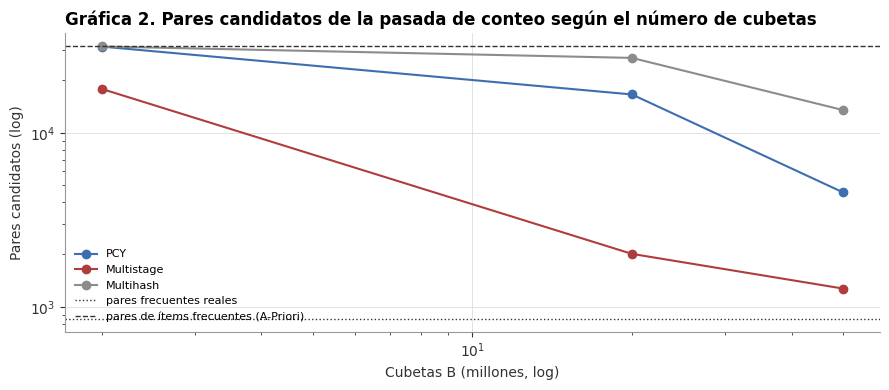

B (millones),2.000003,20.000003,50.000017
variante,,,
Multihash,31363,26958,13522
Multistage,17888,2016,1274
PCY,31324,16621,4552


In [5]:
# Pares candidatos según el número de cubetas B
barrido = []
for B in [2_000_003, 20_000_003, 50_000_017]:
    for variante in ["PCY", "Multistage", "Multihash"]:
        t0 = time.perf_counter()
        _, mem_v, _ = pares_por_hash(indptr, items, N_ITEMS, MS, variante, B=B)
        barrido.append({"B (millones)": B / 1e6, "variante": variante, "pares candidatos": mem_v["pares candidatos"],
                        "segundos": time.perf_counter() - t0, "memoria de cubetas": mem_v["cubetas pasada 1"]})
barrido = pd.DataFrame(barrido)
fig, ax = plt.subplots(figsize=(9, 4))
for variante, color in zip(["PCY", "Multistage", "Multihash"], [AZUL, ROJO, GRIS]):
    d = barrido[barrido["variante"] == variante]
    ax.plot(d["B (millones)"], d["pares candidatos"], marker="o", color=color, label=variante)
ax.axhline(sum(len(k) == 2 for k in frec_apriori), color=TINTA, linestyle=":", linewidth=1, label="pares frecuentes reales")
ax.axhline(F1 * (F1 - 1) // 2, color=TINTA, linestyle="--", linewidth=1, label="pares de ítems frecuentes (A-Priori)")
ax.set_xscale("log")
ax.set_yscale("log")
ax.legend(fontsize=8)
estilo_ejes(ax, "Gráfica 2. Pares candidatos de la pasada de conteo según el número de cubetas",
            "Cubetas B (millones, log)", "Pares candidatos (log)", rejilla="both")
plt.tight_layout()
plt.show()
display(barrido.pivot(index="variante", columns="B (millones)", values="pares candidatos"))

**Observaciones: PCY, Multistage y Multihash**

- **Los cuatro algoritmos encuentran los mismos 857 pares frecuentes** (lo comprueba un `assert`).
- **Aquí no conviene usarlos (tabla).** Con 251 películas frecuentes, el arreglo triangular de A-Priori ocupa 125.5 KB.
  PCY necesita **80 MB** de cubetas en la pasada 1 y tarda **43 s** contra 0.3 s, porque hace *hash* de los 351
  millones de pares de todas las canastas, no solo de los de películas frecuentes. Estos algoritmos están pensados para
  cuando $\binom{|L_1|}{2}$ contadores **no caben** en memoria. Con 5,000 películas frecuentes serían 12.5 millones de
  contadores (50 MB), y con un catálogo de millones de ítems, imposible.
- **El filtro depende del número de cubetas (Gráfica 2).**
  - Con **2 millones** de cubetas, PCY deja pasar **31,324** de 31,375 pares: casi nada. Con 351 millones de
    ocurrencias, cada cubeta acumula en promedio 176 y las cubetas que contienen pares populares rebasan el umbral
    aunque esos pares no sean frecuentes.
  - Con **20 millones**, PCY baja a **16,621** candidatos y con **50 millones** a **4,552**: menos de 1/3 de los pares,
    el punto en que los triples (12 bytes) ya ahorran memoria frente al triangular (4 bytes por par posible).
- **Multistage es el filtro más fino.** Su segunda tabla solo recibe los pares que pasaron la primera, que están menos
  saturados: con 20 millones de cubetas deja **2,016** candidatos y con 50 millones **1,274**, cerca de los 857 reales.
  Cuesta una pasada más.
- **Multihash es el peor aquí.** Partir las cubetas en dos tablas de $B/2$ duplica la saturación de cada una; solo
  conviene cuando el promedio por cubeta está muy por debajo del umbral (MMDS, sección 6.3.3).

<div style="border-left:4px solid #3D6FB0;padding:4px 0 6px 14px;margin:16px 0 6px 0;"><span style="background:#3D6FB0;color:#FFFFFF;border-radius:3px;padding:2px 9px;font-size:11px;letter-spacing:.6px;">REGLAS · SON Y TOIVONEN</span><br/><span style="color:#3D6FB0;font-size:21px;font-weight:700;">4. SON y Toivonen</span></div>



Ambos encuentran **todos** los itemsets frecuentes con a lo más dos pasadas completas, trabajando en memoria con partes
de los datos (MMDS, sección 6.4).

- **SON (Savasere, Omiecinski y Navathe).** Parte las canastas en $p$ trozos y corre A-Priori en cada uno con el
  umbral proporcional $s / p$. Todo itemset frecuente en el total es frecuente en al menos un trozo, así que la
  **unión** de los frecuentes locales contiene a todos los globales. Una segunda pasada cuenta esos candidatos sobre
  todo el conjunto. Es el esquema natural de MapReduce. Usamos $p = 4$.
- **Toivonen.** Corre A-Priori sobre una **muestra** (10 %) con un umbral reducido ($0.8 \cdot s$ proporcional) y
  calcula la **frontera negativa**: los itemsets no frecuentes en la muestra cuyos subconjuntos inmediatos sí lo son.
  Una pasada completa cuenta los frecuentes de la muestra y la frontera negativa. Si ningún itemset de la frontera
  resulta frecuente, el resultado es exacto; si alguno lo es, hay que repetir con otra muestra.

In [6]:
# SON y Toivonen sobre las mismas canastas, verificados contra A-Priori
def sub_canastas(indptr, items, filas):
    tam = indptr[filas + 1] - indptr[filas]
    nuevo = np.zeros(len(filas) + 1, np.int64)
    nuevo[1:] = np.cumsum(tam)
    return nuevo, np.concatenate([items[indptr[f]:indptr[f + 1]] for f in filas])


def contar_todos(indptr, items, itemsets):
    # Soporte en todas las canastas de una colección de itemsets de distintos tamaños
    conteo = {}
    simples = np.bincount(items, minlength=N_ITEMS)
    for k in sorted({len(s) for s in itemsets}):
        nivel = [s for s in itemsets if len(s) == k]
        conteo.update({s: int(simples[s[0]]) for s in nivel} if k == 1 else contar_itemsets(indptr, items, N_ITEMS, nivel))
    return conteo


def son(indptr, items, minsup, p=4):
    candidatos = set()
    for trozo in np.array_split(np.arange(len(indptr) - 1), p):
        ip, it = sub_canastas(indptr, items, trozo)
        candidatos |= set(apriori(ip, it, N_ITEMS, math.ceil(minsup * len(trozo)))[0])
    conteo = contar_todos(indptr, items, candidatos)
    return {s: c for s, c in conteo.items() if c >= minsup * (len(indptr) - 1)}, len(candidatos)


def toivonen(indptr, items, minsup, fraccion=0.10, factor=0.8, max_intentos=5):
    n = len(indptr) - 1
    for intento in range(1, max_intentos + 1):
        muestra = np.sort(np.random.default_rng(SEMILLA + intento).choice(n, int(fraccion * n), replace=False))
        ip, it = sub_canastas(indptr, items, muestra)
        frec_m, _ = apriori(ip, it, N_ITEMS, math.ceil(factor * minsup * len(muestra)))
        frontera = [(i,) for i in range(N_ITEMS) if (i,) not in frec_m]
        por_k = {}
        for s in frec_m:
            por_k.setdefault(len(s), {})[s] = 1
        for k in sorted(por_k):
            frontera += [c for c in generar_candidatos(por_k[k]) if c not in frec_m]
        conteo = contar_todos(indptr, items, list(frec_m) + frontera)
        umbral = minsup * n
        if not any(conteo[s] >= umbral for s in frontera):
            return {s: c for s, c in conteo.items() if c >= umbral}, intento, len(frec_m), len(frontera)
    return None, max_intentos, len(frec_m), len(frontera)


t0 = time.perf_counter()
frec_son, n_cand_son = son(indptr, items, MINSUP)
seg_son = time.perf_counter() - t0
t0 = time.perf_counter()
frec_toiv, intentos, n_frec_muestra, n_frontera = toivonen(indptr, items, MINSUP)
seg_toiv = time.perf_counter() - t0
assert frec_son == frec_apriori
print(f"SON (4 trozos): {seg_son:.2f} s | candidatos de la primera pasada: {n_cand_son:,} | igual a A-Priori: "
      f"{frec_son == frec_apriori}")
print(f"Toivonen (muestra 10 %, umbral 0.8·s): {seg_toiv:.2f} s | intentos: {intentos} | frecuentes en la muestra: "
      f"{n_frec_muestra:,} | frontera negativa: {n_frontera:,} | igual a A-Priori: {frec_toiv == frec_apriori}")
ram("4. SON y Toivonen")

SON (4 trozos): 1.47 s | candidatos de la primera pasada: 2,180 | igual a A-Priori: True
Toivonen (muestra 10 %, umbral 0.8·s): 5.95 s | intentos: 1 | frecuentes en la muestra: 7,749 | frontera negativa: 92,910 | igual a A-Priori: True
[RAM] 4. SON y Toivonen: proceso 647.5 MB | libre en el sistema 6.68 GB


**Observaciones: SON y Toivonen**

- **Los dos dan exactamente los 1,603 itemsets de A-Priori.**
- **SON.** Las cuatro corridas locales generan **2,180** candidatos, solo un 36 % más que los frecuentes reales, y la
  segunda pasada los filtra. Tarda **1.5 s**. Cada trozo solo necesita un cuarto de las canastas en memoria, y las
  dos fases son un *map* y un *reduce*.
- **Toivonen.** Funcionó **al primer intento**: ningún itemset de la frontera negativa resultó frecuente en el
  total. El costo está en la frontera: con el umbral reducido, la muestra tiene **7,749** frecuentes y su frontera
  negativa **92,910** itemsets, 58 veces más que el resultado. Todos se cuentan en la pasada completa (**6 s**).
  Con canastas tan grandes, bajar el umbral de la muestra multiplica los candidatos.

<div style="border-left:4px solid #3D6FB0;padding:4px 0 6px 14px;margin:16px 0 6px 0;"><span style="background:#3D6FB0;color:#FFFFFF;border-radius:3px;padding:2px 9px;font-size:11px;letter-spacing:.6px;">REGLAS · COMPARACIÓN</span><br/><span style="color:#3D6FB0;font-size:21px;font-weight:700;">5. FP-Growth y comparación de los algoritmos</span></div>



**FP-Growth** (Han, Pei y Yin, 2000) no genera candidatos. Comprime las canastas en un árbol de prefijos (*FP-tree*)
ordenado por frecuencia y extrae los frecuentes recursivamente de árboles condicionales. Lo usamos como **referencia**
con `mlxtend`, que necesita la matriz binaria canastas × películas como `DataFrame` de pandas. Medimos su memoria con
`tracemalloc`, que sí ve las asignaciones de pandas y numpy. Para los algoritmos propios reportamos el tamaño de la
estructura de conteo, porque `tracemalloc` no ve la memoria que reserva `numba`.

,pasadas completas,segundos,memoria principal,itemsets
algoritmo,,,,
A-Priori,7,0.87,125.5 KB (triangular de pares),1603
PCY,7,43.47,80.0 MB (cubetas) → 199.5 KB (triples),1603
Multistage,8,50.44,80.0 MB (cubetas) → 24.2 KB (triples),1603
Multihash,7,82.19,80.0 MB (cubetas) → 323.5 KB (triples),1603
SON (4 trozos),2,1.47,1/4 de las canastas a la vez,1603
Toivonen (10 %),1,5.95,muestra del 10 %,1603
FP-Growth (mlxtend),2,253.32,"300.4 MB (pico, tracemalloc)",1603


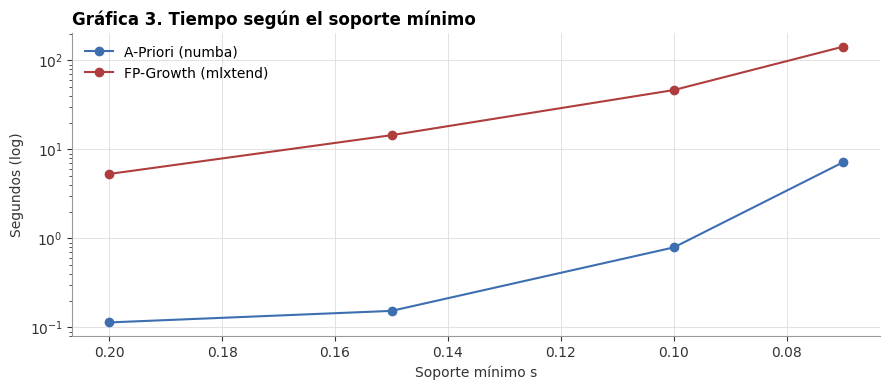

soporte,0.20,0.15,0.10,0.07
itemsets,42.00,165.00,1603.00,16757.00
A-Priori (s),0.11,0.15,0.79,7.20
FP-Growth (s),5.31,14.48,46.55,143.16
tamaño máximo,2.00,3.00,6.00,7.00


[RAM] 5. FP-Growth: proceso 772.9 MB | libre en el sistema 7.49 GB


In [7]:
# FP-Growth (mlxtend) como referencia, tabla comparativa y tiempos según el soporte
binaria = pd.DataFrame(T.toarray().astype(bool))
tracemalloc.start()
t0 = time.perf_counter()
fp = fpgrowth(binaria, min_support=MINSUP, use_colnames=True)
seg_fp = time.perf_counter() - t0
pico_fp = tracemalloc.get_traced_memory()[1]
tracemalloc.stop()
frec_fp = {tuple(sorted(int(i) for i in s)): int(round(v * N_T)) for s, v in zip(fp["itemsets"], fp["support"])}
assert frec_fp == frec_apriori

comparacion = pd.DataFrame([
    {"algoritmo": "A-Priori", "pasadas completas": por_tamano.index.max() + 1, "segundos": seg_apriori,
     "memoria principal": f"{tamano(mem_apriori)} (triangular de pares)", "itemsets": len(frec_apriori)},
    *[{"algoritmo": v, "pasadas completas": r["pasadas para los pares"] + por_tamano.index.max() - 1,
       "segundos": r["segundos (pares)"] + seg_apriori - seg_pares_apriori,
       "memoria principal": f"{tamano(r['cubetas pasada 1'])} (cubetas) → {tamano(r['triples (12 bytes por candidato)'])} (triples)",
       "itemsets": len(frec_apriori)} for v, r in resultados_hash.items()],
    {"algoritmo": "SON (4 trozos)", "pasadas completas": 2, "segundos": seg_son,
     "memoria principal": "1/4 de las canastas a la vez", "itemsets": len(frec_son)},
    {"algoritmo": "Toivonen (10 %)", "pasadas completas": 1 + intentos - 1, "segundos": seg_toiv,
     "memoria principal": "muestra del 10 %", "itemsets": len(frec_toiv)},
    {"algoritmo": "FP-Growth (mlxtend)", "pasadas completas": 2, "segundos": seg_fp,
     "memoria principal": f"{tamano(pico_fp)} (pico, tracemalloc)", "itemsets": len(frec_fp)},
]).set_index("algoritmo")
display(comparacion.round({"segundos": 2}))

# Tiempos de A-Priori y FP-Growth según el soporte mínimo
tiempos = []
for s in [0.20, 0.15, 0.10, 0.07]:
    t0 = time.perf_counter()
    f_a, _ = apriori(indptr, items, N_ITEMS, int(s * N_T))
    t_a = time.perf_counter() - t0
    t0 = time.perf_counter()
    f_f = fpgrowth(binaria, min_support=s)
    tiempos.append({"soporte": s, "itemsets": len(f_a), "A-Priori (s)": t_a, "FP-Growth (s)": time.perf_counter() - t0,
                    "tamaño máximo": max(len(k) for k in f_a)})
tiempos = pd.DataFrame(tiempos).set_index("soporte")
fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(tiempos.index, tiempos["A-Priori (s)"], marker="o", color=AZUL, label="A-Priori (numba)")
ax.plot(tiempos.index, tiempos["FP-Growth (s)"], marker="o", color=ROJO, label="FP-Growth (mlxtend)")
ax.set_yscale("log")
ax.invert_xaxis()
ax.legend()
estilo_ejes(ax, "Gráfica 3. Tiempo según el soporte mínimo", "Soporte mínimo s", "Segundos (log)", rejilla="both")
plt.tight_layout()
plt.show()
display(tiempos.round(2).T)
del binaria
gc.collect()
ram("5. FP-Growth")

**Observaciones: comparación de los algoritmos**

- **Todos coinciden:** 1,603 itemsets, también FP-Growth.
- **Nota sobre los tiempos.** Este notebook se ejecutó mientras corrían otros en paralelo, así que los tiempos
  absolutos son mayores que en solitario (en una corrida aislada, A-Priori tardó 0.5 s y PCY 25 s). Las proporciones
  entre algoritmos se mantienen.
- **Tiempo (tabla y Gráfica 3).**
  - **A-Priori compilado con `numba` es el más rápido** en todo el rango: 0.11 s con $s = 20\,\%$ y 7.2 s con
    $s = 7\,\%$ (16,757 itemsets, hasta 7 películas).
  - FP-Growth de `mlxtend` tarda de **5.3 s a 143 s**: entre 20 y 100 veces más.
  - La comparación no es entre algoritmos puros. `mlxtend` está escrito en Python y pandas, y recibe una matriz densa
    de 20,000 × 5,000; nuestro A-Priori recorre las canastas en código compilado. Aun así, la ventaja teórica de
    FP-Growth (no generar candidatos) no compensa aquí, porque los candidatos de A-Priori son pocos.
- **Memoria.** A-Priori necesita 125 KB para los pares. PCY y sus variantes, 80 MB de cubetas en la pasada 1, que
  después se reducen a un mapa de bits de 2.5 MB más los triples. FP-Growth llega a **300 MB** de pico. SON y Toivonen
  trabajan con fracciones de los datos.
- **Conclusión.** Para estos datos (pocas películas frecuentes, canastas grandes), A-Priori con arreglo triangular es
  la mejor opción. PCY y Multistage serían necesarios si los pares de ítems frecuentes no cupieran en memoria. SON es
  el esquema para distribuir el cálculo.

<div style="border-left:4px solid #3D6FB0;padding:4px 0 6px 14px;margin:16px 0 6px 0;"><span style="background:#3D6FB0;color:#FFFFFF;border-radius:3px;padding:2px 9px;font-size:11px;letter-spacing:.6px;">REGLAS · REGLAS</span><br/><span style="color:#3D6FB0;font-size:21px;font-weight:700;">6. Reglas de asociación</span></div>



Una regla $X \to y$ ("a quienes les gustó $X$ también les gustó $y$") sale de un itemset frecuente $X \cup \{y\}$:

- **soporte** $= \text{sop}(X \cup \{y\}) / n$;
- **confianza** $= \text{sop}(X \cup \{y\}) / \text{sop}(X)$, la probabilidad de que le guste $y$ dado que le gustó todo $X$;
- **lift** $= \text{confianza} / (\text{sop}(y) / n)$: cuántas veces más probable es $y$ dado $X$ que en general. Un lift
  de 1 indica independencia. La confianza sola premia a las películas populares, que aparecen en casi cualquier canasta;
  el lift corrige ese sesgo.

Generamos todas las reglas con consecuente de una película a partir de los itemsets frecuentes con $s = 10\,\%$.

In [8]:
# Reglas X → y con confianza y lift a partir de los itemsets frecuentes
reglas = []
for itemset, sop in frec_apriori.items():
    if len(itemset) < 2:
        continue
    for y in itemset:
        X = tuple(i for i in itemset if i != y)
        conf = sop / frec_apriori[X]
        reglas.append({"X": X, "y": y, "|X|": len(X), "soporte": sop / N_T, "confianza": conf,
                       "lift": conf / (frec_apriori[(y,)] / N_T)})
reglas = pd.DataFrame(reglas)
print(f"{len(reglas):,} reglas | confianza ≥ 0.8: {(reglas['confianza'] >= 0.8).sum():,} | lift > 2: "
      f"{(reglas['lift'] > 2).sum():,} | lift < 1: {(reglas['lift'] < 1).sum():,}")


def mostrar(df):
    return pd.DataFrame({"a quienes les gustó": [" + ".join(titulo(i) for i in X) for X in df["X"]],
                         "también les gustó": [titulo(y) for y in df["y"]],
                         "soporte": df["soporte"].round(3).to_numpy(), "confianza": df["confianza"].round(3).to_numpy(),
                         "lift": df["lift"].round(2).to_numpy()}, index=range(1, len(df) + 1))


print("Reglas de un antecedente con mayor lift:")
display(mostrar(reglas[reglas["|X|"] == 1].nlargest(10, "lift")))
print("Reglas con mayor confianza (cualquier tamaño):")
display(mostrar(reglas.nlargest(10, "confianza")))
print("Reglas de un antecedente con mayor confianza: el consecuente es casi siempre una película muy popular")
display(mostrar(reglas[reglas["|X|"] == 1].nlargest(6, "confianza")))

3,283 reglas | confianza ≥ 0.8: 584 | lift > 2: 2,712 | lift < 1: 0
Reglas de un antecedente con mayor lift:


,a quienes les gustó,también les gustó,soporte,confianza,lift
1,The Lord of the Rings: The Fellowship of the Ring: Extended Editio...,Lord of the Rings: The Two Towers: Extended Edition (2002),0.133,0.908,6.14
2,Lord of the Rings: The Two Towers: Extended Edition (2002),The Lord of the Rings: The Fellowship of the Ring: Extended Editio...,0.133,0.897,6.14
3,Lord of the Rings: The Return of the King: Extended Edition (2003),Lord of the Rings: The Two Towers: Extended Edition (2002),0.124,0.861,5.82
4,Lord of the Rings: The Two Towers: Extended Edition (2002),Lord of the Rings: The Return of the King: Extended Edition (2003),0.124,0.840,5.82
5,Lord of the Rings: The Return of the King: Extended Edition (2003),The Lord of the Rings: The Fellowship of the Ring: Extended Editio...,0.123,0.850,5.82
6,The Lord of the Rings: The Fellowship of the Ring: Extended Editio...,Lord of the Rings: The Return of the King: Extended Edition (2003),0.123,0.840,5.82
7,Star Wars: Episode VI: Return of the Jedi (1983),Star Wars: Episode V: The Empire Strikes Back (1980),0.143,0.863,4.92
8,Star Wars: Episode V: The Empire Strikes Back (1980),Star Wars: Episode VI: Return of the Jedi (1983),0.143,0.813,4.92
9,Star Wars: Episode IV: A New Hope (1977),Star Wars: Episode V: The Empire Strikes Back (1980),0.137,0.856,4.88
10,Star Wars: Episode V: The Empire Strikes Back (1980),Star Wars: Episode IV: A New Hope (1977),0.137,0.782,4.88


Reglas con mayor confianza (cualquier tamaño):


,a quienes les gustó,también les gustó,soporte,confianza,lift
1,Lord of the Rings: The Fellowship of the Ring (2001) + Lord of the...,Lord of the Rings: The Return of the King (2003),0.101,0.976,3.86
2,Lord of the Rings: The Fellowship of the Ring (2001) + The Lord of...,Lord of the Rings: The Return of the King (2003),0.104,0.972,3.84
3,Lord of the Rings: The Fellowship of the Ring (2001) + Lord of the...,Lord of the Rings: The Return of the King (2003),0.105,0.971,3.84
4,Lord of the Rings: The Fellowship of the Ring (2001) + Lord of the...,Lord of the Rings: The Two Towers (2002),0.101,0.971,3.49
5,Lord of the Rings: The Fellowship of the Ring (2001) + Lord of the...,Lord of the Rings: The Return of the King (2003),0.113,0.970,3.83
6,Lord of the Rings: The Fellowship of the Ring (2001) + Lord of the...,Lord of the Rings: The Two Towers (2002),0.113,0.970,3.49
7,Lord of the Rings: The Fellowship of the Ring (2001) + The Lord of...,Lord of the Rings: The Two Towers (2002),0.104,0.969,3.49
8,Lord of the Rings: The Fellowship of the Ring (2001) + Lord of the...,Lord of the Rings: The Two Towers (2002),0.105,0.969,3.49
9,Lord of the Rings: The Fellowship of the Ring (2001) + Lord of the...,Lord of the Rings: The Two Towers (2002),0.101,0.967,3.48
10,Lord of the Rings: The Two Towers: Extended Edition (2002) + The L...,Lord of the Rings: The Return of the King (2003),0.105,0.967,3.82


Reglas de un antecedente con mayor confianza: el consecuente es casi siempre una película muy popular


,a quienes les gustó,también les gustó,soporte,confianza,lift
1,Lord of the Rings: The Two Towers: Extended Edition (2002),Lord of the Rings: The Return of the King (2003),0.135,0.911,3.60
2,The Lord of the Rings: The Fellowship of the Ring: Extended Editio...,Lord of the Rings: The Two Towers (2002),0.133,0.910,3.28
3,Lord of the Rings: The Two Towers: Extended Edition (2002),Lord of the Rings: The Two Towers (2002),0.135,0.909,3.27
4,The Lord of the Rings: The Fellowship of the Ring: Extended Editio...,Lord of the Rings: The Two Towers: Extended Edition (2002),0.133,0.908,6.14
5,The Lord of the Rings: The Fellowship of the Ring: Extended Editio...,Lord of the Rings: The Return of the King (2003),0.133,0.908,3.59
6,Lord of the Rings: The Return of the King: Extended Edition (2003),Lord of the Rings: The Return of the King (2003),0.131,0.907,3.58


**Observaciones: reglas de asociación**

- **Volumen.** Hay **3,283** reglas; 584 tienen confianza ≥ 0.8 y **ninguna** tiene lift < 1. Entre películas
  populares, que te guste una nunca hace menos probable que te guste otra.
- **Las de mayor lift son sagas.**
  - Las ediciones extendidas de *El Señor de los Anillos* entre sí tienen lift de hasta **6.1**: a quien le gustó una
    tiene 6 veces más probabilidad que el promedio de que le guste otra.
  - Después vienen las tres películas originales de *Star Wars* (lift ≈ 4.9).
- **Las de mayor confianza tienen antecedentes grandes.** "Fellowship + otras dos de la saga → Return of the King"
  llega a **0.976**.
- **La confianza sola engaña.** Las reglas de un antecedente con mayor confianza terminan casi siempre en una película
  muy popular. *The Return of the King* aparece como consecuente con confianza ~0.91 porque le gustó a casi todos los que
  ven la saga. El lift separa la asociación real de la popularidad del consecuente.

**Recomendador basado en reglas.** Con $s = 10\,\%$ solo hay reglas sobre 251 películas populares. Para recomendar sobre
todo S bajamos el soporte a **2 %** (400 canastas) y usamos solo reglas de un antecedente (pares frecuentes, A-Priori
con $k \le 2$). Para cada usuario, el puntaje de una película $y$ es la **máxima confianza** de las reglas $x \to y$ con
$x$ entre las películas que le gustaron. Como variante, usamos el **máximo lift**. Las películas sin regla aplicable
quedan detrás, ordenadas por popularidad. Evaluamos con el mismo top-N de prueba de los notebooks 2 y 3.

In [9]:
# Reglas de pares con s = 2 % y top-N por máxima confianza y por máximo lift
REL_PROBE = [np.load(RUTA_PROCESADOS / f"S_probe_{x}.npy") for x in "umr"]
REL = sp.csr_matrix((np.ones((REL_PROBE[2] >= 4).sum(), dtype=bool), (REL_PROBE[0][REL_PROBE[2] >= 4], REL_PROBE[1][REL_PROBE[2] >= 4])),
                    shape=S_R.shape)
U_EVAL = np.load(RUTA_PROCESADOS / "S_usuarios_topn.npy")
K = 10
DESCUENTO = 1 / np.log2(np.arange(2, K + 2))
popularidad = np.diff(S_R.tocsc().indptr).astype(np.float32)


def evaluar_topn(puntuar, usuarios=U_EVAL, lote=500):
    p, r, n = [], [], []
    for a in range(0, len(usuarios), lote):
        us = usuarios[a:a + lote]
        punt = np.array(puntuar(us), dtype=np.float32)
        f, c = S_R[us].nonzero()
        punt[f, c] = -np.inf
        top = np.argpartition(-punt, K, axis=1)[:, :K]
        top = np.take_along_axis(top, np.argsort(-np.take_along_axis(punt, top, 1), axis=1), 1)
        rel_lote = REL[us].toarray()
        aciertos = np.take_along_axis(rel_lote, top, 1)
        n_rel = rel_lote.sum(1)
        p.append(aciertos.sum(1) / K)
        r.append(aciertos.sum(1) / n_rel)
        n.append((aciertos * DESCUENTO).sum(1) / np.cumsum(DESCUENTO)[np.minimum(n_rel, K) - 1])
    return {f"P@{K}": float(np.concatenate(p).mean()), f"R@{K}": float(np.concatenate(r).mean()),
            f"NDCG@{K}": float(np.concatenate(n).mean())}


t0 = time.perf_counter()
frec_2, _ = apriori(indptr, items, N_ITEMS, int(0.02 * N_T), max_k=2)
sop1 = np.zeros(N_ITEMS)
for (i,), c in ((k, c) for k, c in frec_2.items() if len(k) == 1):
    sop1[i] = c
CONF, LIFT = np.zeros((N_ITEMS, N_ITEMS), np.float32), np.zeros((N_ITEMS, N_ITEMS), np.float32)
for (i, j), c in ((k, c) for k, c in frec_2.items() if len(k) == 2):
    CONF[i, j], CONF[j, i] = c / sop1[i], c / sop1[j]
    LIFT[i, j] = LIFT[j, i] = c * N_T / (sop1[i] * sop1[j])
seg_reglas = time.perf_counter() - t0
EPS = 1e-6 * popularidad / popularidad.max()


def puntuar_reglas(M):
    def puntuar(us):
        P = np.empty((len(us), N_ITEMS), np.float32)
        for t, u in enumerate(us):
            g = GUSTA.indices[GUSTA.indptr[u]:GUSTA.indptr[u + 1]]
            P[t] = (M[g].max(axis=0) if len(g) else 0) + EPS
        return P
    return puntuar


sp.save_npz(RUTA_PROCESADOS / "modelos" / "reglas_confianza_S.npz", sp.csr_matrix(CONF))
topn_conf = evaluar_topn(puntuar_reglas(CONF))
topn_lift = evaluar_topn(puntuar_reglas(LIFT))
guardar_resultado("Reglas de asociación (S)", tipo="top-N", escala="S (reglas de 20,000 canastas)",
                  segundos_entrenamiento=seg_reglas, configuracion="pares con s = 2 %, puntaje = máxima confianza", **topn_conf)
guardar_resultado("Reglas de asociación, lift (S)", tipo="top-N", escala="S (reglas de 20,000 canastas)",
                  segundos_entrenamiento=seg_reglas, configuracion="pares con s = 2 %, puntaje = máximo lift", **topn_lift)
referencias = {m: json.load(open(RUTA_RESULTADOS / f"{m}.json", encoding="utf-8"))
               for m in ["Popularidad", "kNN ítem-ítem (suma de similitudes)", "PureSVD (S)"]}
display(pd.DataFrame([{"modelo": m, **{k: v[k] for k in topn_conf}} for m, v in referencias.items()]
                     + [{"modelo": "reglas: máxima confianza", **topn_conf}, {"modelo": "reglas: máximo lift", **topn_lift}])
        .set_index("modelo").round(4))
print(f"Películas con soporte ≥ 2 %: {(sop1 > 0).sum():,} | reglas de pares: {2 * sum(len(k) == 2 for k in frec_2):,} | "
      f"{seg_reglas:.1f} s")
ram("6. reglas")

,P@10,R@10,NDCG@10
modelo,,,
Popularidad,0.0053,0.0248,0.0146
kNN ítem-ítem (suma de similitudes),0.0162,0.0780,0.0490
PureSVD (S),0.0189,0.0915,0.0554
reglas: máxima confianza,0.0103,0.0478,0.0305
reglas: máximo lift,0.0075,0.0374,0.0241


Películas con soporte ≥ 2 %: 1,355 | reglas de pares: 213,780 | 1.4 s
[RAM] 6. reglas: proceso 1.01 GB | libre en el sistema 7.25 GB


**Observaciones: recomendador basado en reglas**

- **Las reglas de pares superan a la popularidad.** La máxima confianza da P@10 = **0.0103**, R@10 = **0.0478** y
  NDCG@10 = **0.0305**, el doble que la popularidad (0.0053 / 0.0248 / 0.0146).
- **Quedan debajo del kNN por suma de similitudes (0.0490) y de PureSVD (0.0554).** Las reglas solo cubren las 1,355
  películas con soporte ≥ 2 %. Además, la **máxima** confianza usa una sola película del usuario como evidencia,
  mientras que el kNN **suma** la de todas.
- **Ordenar por lift es peor (0.0241).** El lift favorece consecuentes poco populares con asociaciones fuertes, y en el
  probe los usuarios califican sobre todo películas populares. Es el mismo conflicto entre predecir y ordenar de los
  notebooks 2 y 3.
- **Costo.** Las reglas de pares con $s = 2\,\%$ se calculan en **1.4 s**; son 213,780 reglas.

<div style="border-left:4px solid #3D6FB0;padding:4px 0 6px 14px;margin:16px 0 6px 0;"><span style="background:#3D6FB0;color:#FFFFFF;border-radius:3px;padding:2px 9px;font-size:11px;letter-spacing:.6px;">REGLAS · SECUENCIAS</span><br/><span style="color:#3D6FB0;font-size:21px;font-weight:700;">7. PrefixSpan: patrones secuenciales</span></div>



**Secuencias.** Para cada usuario ordenamos por fecha las películas que le gustaron (rating ≥ 4). Por las ráfagas del
notebook 1, las películas calificadas **el mismo día** forman un solo elemento (un *itemset*) de la secuencia, sin un
orden inventado dentro del día. Un patrón $\langle a, b \rangle$ significa que a un usuario le gustó $a$ y, **en un día
posterior**, $b$. Lo que pasa dentro de un mismo día ya lo capturan las canastas de las secciones anteriores.

**Escala.** Usamos 10,000 de los 20,000 usuarios y las **500 películas con más "me gusta"**. Las demás se quitan de
las secuencias.

**PrefixSpan** (Pei *et al.*, 2001), implementado por nosotros. Crece los patrones por prefijos: para un prefijo
$\alpha$, la **base proyectada** guarda en cada secuencia el día de la primera aparición del prefijo, y los ítems
frecuentes en los días posteriores son las extensiones de $\alpha$. No genera candidatos y cada proyección solo mira
sufijos. Las secuencias se guardan como tres arreglos (secuencia, día, película) ordenados, y cada proyección es un
vector con el día de corte de cada secuencia, así que contar es un filtrado vectorizado con `numpy`.

In [10]:
def prefixspan(seq, dia, item, n_seq, n_items, minsup, max_len=3):
    # PrefixSpan con extensiones a días posteriores: filas ordenadas por (secuencia, día); la proyección guarda, por
    # secuencia, el día del último elemento del prefijo (las extensiones se buscan estrictamente después)
    patrones = {}
    INF = np.iinfo(np.int32).max

    def crecer(prefijo, umbral):
        filas = np.flatnonzero(dia > umbral[seq])
        claves = np.unique(seq[filas].astype(np.int64) * n_items + item[filas])
        soporte = np.bincount(claves % n_items, minlength=n_items)
        for x in np.flatnonzero(soporte >= minsup):
            patron = prefijo + (int(x),)
            patrones[patron] = int(soporte[x])
            if len(patron) < max_len:
                f = filas[item[filas] == x]
                s_x, primera = np.unique(seq[f], return_index=True)  # primera aparición de x después del prefijo
                nuevo = np.full(n_seq, INF, np.int32)
                nuevo[s_x] = dia[f[primera]]
                crecer(patron, nuevo)

    crecer((), np.full(n_seq, -1, np.int32))
    return patrones


# Secuencias de 10,000 usuarios con las 500 películas con más "me gusta"
filas_S = np.repeat(np.arange(n_S_usr, dtype=np.int32), np.diff(S_R.indptr))
USUARIOS_SEQ = USUARIOS_T[:10_000]
local = np.full(n_S_usr, -1, np.int32)
local[USUARIOS_SEQ] = np.arange(len(USUARIOS_SEQ))
TOP_SEQ = np.argsort(-soporte_item)[:500]
item_seq = np.full(N_ITEMS, -1, np.int32)
item_seq[TOP_SEQ] = np.arange(500)
sel = (S_R.data >= 4) & (local[filas_S] >= 0) & (item_seq[S_R.indices] >= 0)
seq, it_s, dia_s = local[filas_S[sel]], item_seq[S_R.indices[sel]], S_dias[sel].astype(np.int32)
orden = np.lexsort((dia_s, seq))
seq, it_s, dia_s = seq[orden], it_s[orden], dia_s[orden]

dias_distintos = pd.Series(seq.astype(np.int64) * 10_000 + dia_s).drop_duplicates().floordiv(10_000).value_counts()
print(f"Secuencias con al menos una película: {len(dias_distintos):,} | ocurrencias: {len(seq):,} | días distintos por "
      f"secuencia: mediana {dias_distintos.median():.0f}, media {dias_distintos.mean():.1f} | secuencias de un solo día: "
      f"{pct((dias_distintos == 1).mean(), 1)}")

barrido_ps = []
for s in [0.10, 0.07, 0.05, 0.03]:
    t0 = time.perf_counter()
    pat = prefixspan(seq, dia_s, it_s, len(USUARIOS_SEQ), 500, int(s * len(USUARIOS_SEQ)), max_len=3)
    largos = pd.Series([len(p) for p in pat]).value_counts()
    barrido_ps.append({"soporte": s, "segundos": time.perf_counter() - t0, "patrones": len(pat),
                       **{f"longitud {k}": int(largos.get(k, 0)) for k in [1, 2, 3]}})
    if s == 0.05:
        patrones = pat
display(pd.DataFrame(barrido_ps).set_index("soporte").round(1))
ram("7. PrefixSpan")

Secuencias con al menos una película: 9,860 | ocurrencias: 584,491 | días distintos por secuencia: mediana 8, media 14.5 | secuencias de un solo día: 14.6 %


,segundos,patrones,longitud 1,longitud 2,longitud 3
soporte,,,,,
0.10,8.5,257,253,4,0
0.07,13.0,543,420,123,0
0.05,24.5,1670,500,1170,0
0.03,119.6,10892,500,10182,210


[RAM] 7. PrefixSpan: proceso 1.14 GB | libre en el sistema 5.60 GB


In [11]:
# Reglas secuenciales a → b (b en un día posterior) con soporte 5 %: confianza, lift y asimetría
n_seq = len(USUARIOS_SEQ)
sop_seq = {p[0]: c for p, c in patrones.items() if len(p) == 1}
secuenciales = pd.DataFrame([{"a": p[0], "b": p[1], "soporte": c / n_seq, "confianza": c / sop_seq[p[0]],
                              "lift": c / sop_seq[p[0]] / (sop_seq[p[1]] / n_seq)}
                             for p, c in patrones.items() if len(p) == 2])
# Soporte exacto de <x, y> (y en un día posterior a x): primera fecha de x < última fecha de y en la secuencia.
# Sirve para medir b → a aunque no sea frecuente, y para comprobar los soportes de PrefixSpan
primera = np.full((n_seq, 500), np.iinfo(np.int32).max, np.int32)
ultima = np.full((n_seq, 500), -1, np.int32)
np.minimum.at(primera, (seq, it_s), dia_s)
np.maximum.at(ultima, (seq, it_s), dia_s)
soporte_seq = lambda x, y: int((primera[:, x] < ultima[:, y]).sum())
assert all(soporte_seq(p[0], p[1]) == c for p, c in patrones.items() if len(p) == 2)
secuenciales["confianza b → a"] = [soporte_seq(b, a) / sop_seq[b] for a, b in zip(secuenciales["a"], secuenciales["b"])]
secuenciales["asimetría"] = secuenciales["confianza"] - secuenciales["confianza b → a"]


def mostrar_seq(df):
    return pd.DataFrame({"primero le gustó": [titulo(TOP_SEQ[a]) for a in df["a"]],
                         "después le gustó": [titulo(TOP_SEQ[b]) for b in df["b"]],
                         "soporte": df["soporte"].round(3).to_numpy(), "confianza": df["confianza"].round(3).to_numpy(),
                         "confianza b → a": df["confianza b → a"].round(3).to_numpy(),
                         "lift": df["lift"].round(2).to_numpy()}, index=range(1, len(df) + 1))


print(f"{len(secuenciales):,} reglas secuenciales de un paso | mayor lift:")
display(mostrar_seq(secuenciales.nlargest(10, "lift")))
print("Mayor asimetría: el orden importa (a → b mucho más frecuente que b → a; soporte de PrefixSpan verificado)")
display(mostrar_seq(secuenciales.nlargest(10, "asimetría")))

1,170 reglas secuenciales de un paso | mayor lift:


,primero le gustó,después le gustó,soporte,confianza,confianza b → a,lift
1,"Monsters, Inc. (2001)",Toy Story (1995),0.052,0.221,0.034,2.46
2,Lord of the Rings: The Fellowship of the Ring (2001),The Lord of the Rings: The Fellowship of the Ring: Extended Editio...,0.097,0.356,0.054,2.39
3,Lord of the Rings: The Fellowship of the Ring (2001),Lord of the Rings: The Return of the King: Extended Edition (2003),0.094,0.345,0.061,2.35
4,Lord of the Rings: The Fellowship of the Ring (2001),Lord of the Rings: The Two Towers: Extended Edition (2002),0.095,0.350,0.062,2.34
5,X2: X-Men United (2003),The Lord of the Rings: The Fellowship of the Ring: Extended Editio...,0.050,0.345,0.051,2.32
6,Lord of the Rings: The Two Towers (2002),The Lord of the Rings: The Fellowship of the Ring: Extended Editio...,0.096,0.340,0.044,2.29
7,Lord of the Rings: The Return of the King (2003),The Lord of the Rings: The Fellowship of the Ring: Extended Editio...,0.087,0.339,0.067,2.28
8,Lord of the Rings: The Return of the King (2003),Lord of the Rings: The Return of the King: Extended Edition (2003),0.085,0.332,0.074,2.27
9,Finding Nemo (Widescreen) (2003),Toy Story (1995),0.054,0.203,0.036,2.26
10,Lord of the Rings: The Two Towers (2002),Lord of the Rings: The Return of the King: Extended Edition (2003),0.093,0.329,0.050,2.25


Mayor asimetría: el orden importa (a → b mucho más frecuente que b → a; soporte de PrefixSpan verificado)


,primero le gustó,después le gustó,soporte,confianza,confianza b → a,lift
1,X2: X-Men United (2003),The Incredibles (2004),0.062,0.423,0.043,1.78
2,Minority Report (2002),The Incredibles (2004),0.057,0.386,0.039,1.62
3,Reservoir Dogs (1992),The Shawshank Redemption: Special Edition (1994),0.054,0.402,0.062,1.49
4,The Terminator (1984),The Incredibles (2004),0.056,0.382,0.043,1.60
5,Harry Potter and the Prisoner of Azkaban (2004),The Incredibles (2004),0.062,0.392,0.055,1.65
6,Kill Bill: Vol. 2 (2004),The Incredibles (2004),0.058,0.367,0.033,1.54
7,X-Men (2000),The Incredibles (2004),0.056,0.386,0.054,1.62
8,"Crouching Tiger, Hidden Dragon (2000)",The Shawshank Redemption: Special Edition (1994),0.052,0.396,0.065,1.46
9,Lethal Weapon (1987),The Incredibles (2004),0.062,0.358,0.033,1.50
10,X2: X-Men United (2003),Spider-Man 2 (2004),0.056,0.384,0.060,1.87


**Observaciones y decisión: patrones secuenciales**

- **Secuencias cortas.** Las 9,860 secuencias tienen una mediana de **8** días distintos (media 14.5) y el **14.6 %**
  ocurre en un solo día: las ráfagas del notebook 1 reducen la información de orden.
- **Soporte (tabla).** Con $s = 10\,\%$ apenas hay 4 patrones de longitud 2; con **5 %** hay **1,170** (25 s), y los
  de longitud 3 aparecen hasta $s = 3\,\%$ (210 patrones, 2 minutos). **Decisión:** $s = 5\,\%$ y reglas de un
  paso $a 	o b$.
- **PrefixSpan cuenta bien.** Los soportes de los 1,170 patrones coinciden con un conteo directo (primera fecha de $a$
  anterior a la última de $b$; lo comprueba un `assert`).
- **Las reglas con mayor lift siguen sagas y formatos en su orden natural.**
  - Primero *Fellowship of the Ring* en cine y, días después, las **ediciones extendidas**: confianza 0.35, contra
    0.05–0.07 en sentido inverso. Las extendidas salieron en DVD meses después de cada película.
  - *Monsters, Inc.* y *Finding Nemo* llevan a *Toy Story*: a quien le gustó una película reciente de Pixar le gusta
    después la primera.
- **El orden refleja sobre todo el calendario de estrenos.** Las reglas más asimétricas terminan en estrenos de 2004:
  *The Incredibles* aparece después de *X2*, *Minority Report*, *The Terminator* o *Kill Bill 2* con confianza
  0.36–0.42, y al revés solo 0.03–0.06. No es que ver *X2* lleve a *The Incredibles*: *The Incredibles* no existía
  cuando la mayoría calificó *X2*. Lo mismo pasa con la edición especial de *The Shawshank Redemption*.

**Recomendación de la siguiente película.** Con las reglas secuenciales $a \to b$ construimos un recomendador. Para cada
usuario de la evaluación top-N tomamos las películas que le gustaron en sus **3 últimos días** con ratings de
entrenamiento, y el puntaje de $b$ es la máxima confianza de las reglas $a \to b$ con $a$ en ese conjunto. Las películas
sin regla quedan detrás, ordenadas por popularidad. Como el probe contiene justamente los ratings posteriores al
entrenamiento, es la evaluación natural de "lo siguiente que calificará". Lo comparamos con las reglas de co-ocurrencia
de la sección 6, que ignoran el orden.

In [12]:
# Top-N de la siguiente película con reglas secuenciales
CONF_SEQ = np.zeros((N_ITEMS, N_ITEMS), np.float32)
CONF_SEQ[TOP_SEQ[secuenciales["a"]], TOP_SEQ[secuenciales["b"]]] = secuenciales["confianza"].to_numpy()


def puntuar_siguiente(us):
    P = np.empty((len(us), N_ITEMS), np.float32)
    for t, u in enumerate(us):
        a, b = S_R.indptr[u], S_R.indptr[u + 1]
        g = (S_R.data[a:b] >= 4)
        dias_u = S_dias[a:b][g]
        recientes = S_R.indices[a:b][g][dias_u >= np.unique(dias_u)[-3:].min()] if g.any() else np.zeros(0, np.int32)
        P[t] = (CONF_SEQ[recientes].max(axis=0) if len(recientes) else 0) + EPS
    return P


sp.save_npz(RUTA_PROCESADOS / "modelos" / "reglas_secuenciales_S.npz", sp.csr_matrix(CONF_SEQ))
t0 = time.perf_counter()
topn_seq = evaluar_topn(puntuar_siguiente)
guardar_resultado("PrefixSpan siguiente película (S)", tipo="top-N", escala="S (patrones de 10,000 secuencias, 500 películas)",
                  segundos_topn=time.perf_counter() - t0,
                  configuracion="reglas a → b con s = 5 %, últimos 3 días del usuario, máxima confianza", **topn_seq)
display(pd.DataFrame([{"modelo": "popularidad", **{k: referencias["Popularidad"][k] for k in topn_seq}},
                      {"modelo": "reglas de co-ocurrencia (máxima confianza)", **topn_conf},
                      {"modelo": "PrefixSpan: siguiente película", **topn_seq}]).set_index("modelo").round(4))
cubiertos = np.mean([np.isin(REL[u].indices, TOP_SEQ).any() for u in U_EVAL])
print(f"Usuarios evaluados con al menos una película relevante entre las 500 de las secuencias: {pct(cubiertos, 1)}")
ram("7. siguiente película")

,P@10,R@10,NDCG@10
modelo,,,
popularidad,0.0053,0.0248,0.0146
reglas de co-ocurrencia (máxima confianza),0.0103,0.0478,0.0305
PrefixSpan: siguiente película,0.0077,0.0358,0.0215


Usuarios evaluados con al menos una película relevante entre las 500 de las secuencias: 65.4 %
[RAM] 7. siguiente película: proceso 1.28 GB | libre en el sistema 5.47 GB


**Observaciones: recomendación de la siguiente película**

- **Resultado.** P@10 = **0.0077**, R@10 = **0.0358** y NDCG@10 = **0.0215**. Supera a la popularidad (0.0146), pero
  queda **debajo de las reglas de co-ocurrencia** (0.0305), que ignoran el orden.
- **Por qué el orden ayuda poco aquí.**
  - Las secuencias usan solo las **500** películas con más "me gusta". El **34.6 %** de los usuarios evaluados no tiene
    ninguna película relevante entre ellas: para ellos solo queda el respaldo por popularidad.
  - Solo miramos los **3 últimos días** del usuario, una evidencia más corta que su historial completo.
  - Las ráfagas del notebook 1 diluyen el orden: muchos usuarios califican casi todo en pocos días (mediana de **8**
    días distintos por secuencia; 14.6 % en un solo día).
- **Conclusión.** En el Netflix Prize la fecha es la de la calificación, no la de cuándo se vio la película, y la
  secuencia aporta menos que el conjunto. Con datos de visualización (*streaming*) el orden tendría más sentido.

<div style="border-left:4px solid #3D6FB0;padding:4px 0 6px 14px;margin:16px 0 6px 0;"><span style="background:#3D6FB0;color:#FFFFFF;border-radius:3px;padding:2px 9px;font-size:11px;letter-spacing:.6px;">REGLAS · RESUMEN</span><br/><span style="color:#3D6FB0;font-size:21px;font-weight:700;">8. Resumen</span></div>

In [13]:
# Registro de memoria
display(pd.DataFrame(registro_ram).set_index("paso"))

,RAM del proceso,RAM libre del sistema
paso,,
inicio,176.4 MB,7.23 GB
1. canastas,532.9 MB,6.88 GB
3. PCY y variantes,630.5 MB,6.81 GB
4. SON y Toivonen,647.5 MB,6.68 GB
5. FP-Growth,772.9 MB,7.49 GB
6. reglas,1.01 GB,7.25 GB
7. PrefixSpan,1.14 GB,5.60 GB
7. siguiente película,1.28 GB,5.47 GB


**Resumen**

| Recomendador (top-N en el probe de S) | P@10 | R@10 | NDCG@10 |
|---|---|---|---|
| Popularidad | 0.0053 | 0.0248 | 0.0146 |
| Reglas de pares, máxima confianza ($s = 2\,\%$) | **0.0103** | **0.0478** | **0.0305** |
| Reglas de pares, máximo lift | 0.0075 | 0.0374 | 0.0241 |
| PrefixSpan: siguiente película ($s = 5\,\%$) | 0.0077 | 0.0358 | 0.0215 |

- **Itemsets frecuentes.** Los siete algoritmos dan los mismos 1,603 itemsets con $s = 10\,\%$. Con pocas películas
  frecuentes y canastas grandes, A-Priori compilado es el más rápido y el que menos memoria usa. PCY y sus variantes
  solo filtran bien con suficientes cubetas: Multistage reduce los candidatos de 31,375 a 1,274 con 50 millones de
  cubetas. SON y Toivonen aciertan con dos pasadas y una pasada (al primer intento), respectivamente.
- **Reglas.** Las asociaciones más fuertes son sagas (*El Señor de los Anillos*, *Star Wars*). El lift corrige el sesgo
  de la confianza hacia lo popular, pero para recomendar la confianza funciona mejor.
- **Secuencias.** PrefixSpan no encuentra patrones de longitud 3 hasta bajar el soporte a 3 %. El orden refleja sobre
  todo cuándo se estrenaron las películas y cuándo salieron las ediciones extendidas, y no mejora a las reglas sin
  orden.
- **Memoria.** El pico fue de **1.28 GB** del proceso.